# 06 Training
Training is run from the command line so it is resumable and logged (`scripts/run_face_v3_pointnet.ps1`). This notebook inspects the finished runs:
configuration, hardware, duration, health warnings (NaN, exploding gradients, collapsing or inflating uncertainty) and learning curves. A falling
training loss alone is not treated as convergence: validation error and calibration are checked too.

In [1]:
import sys, pathlib, os, json
ROOT = pathlib.Path.cwd()
while not (ROOT / 'src').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
import numpy as np, matplotlib
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
REAL, RUN, RES = 'UNCERTAFACE_DATA_REAL', 'experiments/runs/face_v3_pn', 'reports/results/face_v3_pn'
if not pathlib.Path(REAL).exists():
    raise SystemExit('Build the real-skull dataset first (README: fetch_mug500, prepare_mug500, build_dataset).')

In [2]:
# summary of both finished runs
for name in ['face_v3', 'face_v3_pn']:
    e = json.load(open(f'experiments/runs/{name}/experiment.json'))
    print(name, {k: e[k] for k in ['status', 'epochs_run', 'best_epoch', 'monitor', 'best_monitor', 'duration_s', 'model_params']})
    print('   hardware:', e['hardware'], '| seed:', e.get('seed'), '| warnings:', len(e['all_warnings']))

face_v3 {'status': 'early_stopped', 'epochs_run': 142, 'best_epoch': 91, 'monitor': 'val_nll_mm', 'best_monitor': 1.8030412991841633, 'duration_s': 3082.777698278427, 'model_params': 787190}
   hardware: {'platform': 'Windows-10-10.0.26200-SP0', 'python': '3.11.9', 'torch': '2.5.1+cu121', 'device': 'cuda', 'gpu': 'NVIDIA GeForce RTX 3050 6GB Laptop GPU', 'cuda': '12.1'} | seed: 0 | warnings: 1
face_v3_pn {'status': 'completed', 'epochs_run': 150, 'best_epoch': 140, 'monitor': 'val_nll_mm', 'best_monitor': 1.7000970244407654, 'duration_s': 2174.0749485492706, 'model_params': 619062}
   hardware: {'platform': 'Windows-10-10.0.26200-SP0', 'python': '3.11.9', 'torch': '2.5.1+cu121', 'device': 'cuda', 'gpu': 'NVIDIA GeForce RTX 3050 6GB Laptop GPU', 'cuda': '12.1'} | seed: 0 | warnings: 0


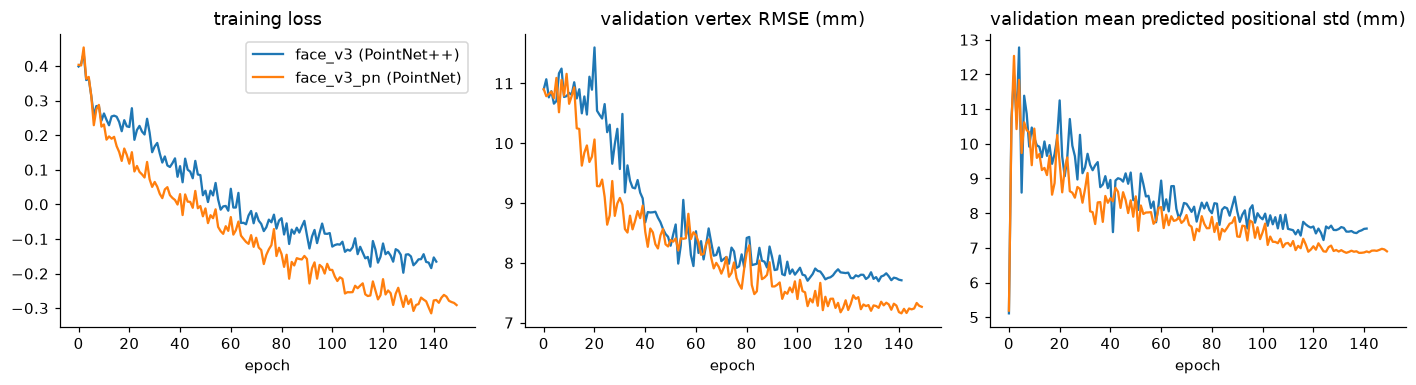

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for name, c in [('face_v3 (PointNet++)', 'tab:blue'), ('face_v3_pn (PointNet)', 'tab:orange')]:
    h = json.load(open(f"experiments/runs/{name.split()[0]}/history.json")); ep = [x['epoch'] for x in h]
    ax[0].plot(ep, [x['train_loss'] for x in h], c=c, label=name); ax[1].plot(ep, [x['val_rmse_mm'] for x in h], c=c); ax[2].plot(ep, [x['val_pos_std_mm'] for x in h], c=c)
ax[0].set_title('training loss'); ax[1].set_title('validation vertex RMSE (mm)'); ax[2].set_title('validation mean predicted positional std (mm)')
for a in ax: a.set_xlabel('epoch')
ax[0].legend(); plt.tight_layout(); plt.show()

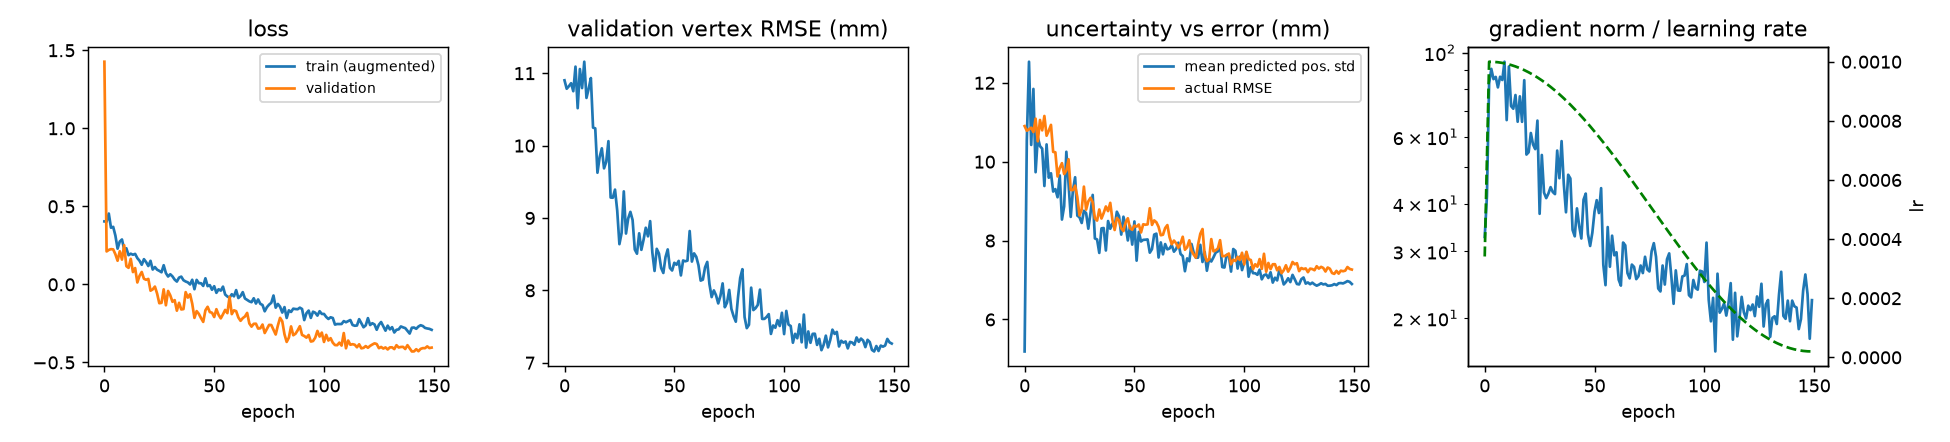

In [4]:
from IPython.display import Image, display
display(Image(RES + '/training_curves.png'))

The 60-epoch ablation runs (`abl_*`) use the same protocol; their histories are in `experiments/runs/abl_*/` and summarised in notebook 08.